# Step 7 — Reading a candidate page

Steps 1–6 turned 4,710 stars into a short ranked list. `src/report.py` (step 7) draws one page
per signal. This notebook is about **using** those pages: what each panel must look like for a
planet, the physical quantities printed on the page and where they come from, and how to grade
a candidate by eye. It does not re-implement the plotting. It imports the page-drawing
functions from `src/report.py` and spends its time on interpretation.

Why a human still looks: vetting is a set of thresholds on numbers. A human sees the *whole*
light curve at once and notices things no single number captures: a ramp under every transit,
three glitches lined up by chance, a star that is obviously variable. The first full review of
this sector changed four vetting tests (notebook 5, §12.1).

Sections:

1. Inputs
2. The summary page: the whole pipeline in one figure
3. Physical quantities on the page: orbit, irradiation, equilibrium temperature
4. Where the candidates sit among known M-dwarf planets
5. Anatomy of a page, on a real planet (LHS 3844 b)
6. The review procedure, with four worked cases
7. From review to pipeline changes

## 1. Inputs

In [1]:
import json
import os
from pathlib import Path

import dotenv
import numpy as np
import pandas as pd

import sys
sys.path.insert(0, "..")  # so `src` is importable from notebooks/
from src import report
from src.vet import _phase_time

%matplotlib inline
import matplotlib.pyplot as plt

ROOT = Path("..")
dotenv.load_dotenv(ROOT / ".env")
SECTOR = int(os.environ["SECTOR"])
DATA_DIR = ROOT / "data"
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 200)

known = pd.read_parquet(DATA_DIR / "search" / f"sector_{SECTOR}_known.parquet").set_index("tic_id")
targets = pd.read_parquet(DATA_DIR / "targets" / f"sector_{SECTOR}.parquet").set_index("tic_id")
manifest = pd.read_parquet(DATA_DIR / "targets" / f"sector_{SECTOR}_manifest.parquet").set_index("tic_id")
detrend = pd.read_parquet(DATA_DIR / "targets" / f"sector_{SECTOR}_detrend.parquet").set_index("tic_id")
pages = pd.read_csv(DATA_DIR / "reports" / f"sector_{SECTOR}_candidates.csv").fillna({"flags": "", "failed": ""})
summary = json.loads((DATA_DIR / "reports" / f"sector_{SECTOR}_summary.json").read_text())
DUMPS = json.loads((DATA_DIR / "search" / f"sector_{SECTOR}_vetted_meta.json").read_text())["momentum_dumps_btjd"]
print(f"{len(pages)} report pages; classes: {pages.known_class.value_counts().to_dict()}")

51 report pages; classes: {'new': 29, 'neighbour': 12, 'known_planet': 9, 'ctoi': 1}


## 2. The summary page

The first page of the PDF is the funnel: how many stars or signals survive each step. Read it
from top to bottom. The grey bars are data processing, where losses should be small (a missing
light curve, an empty file). The blue bars are vetting tests, applied in sequence, so each bar
shows what is left *after* that test.

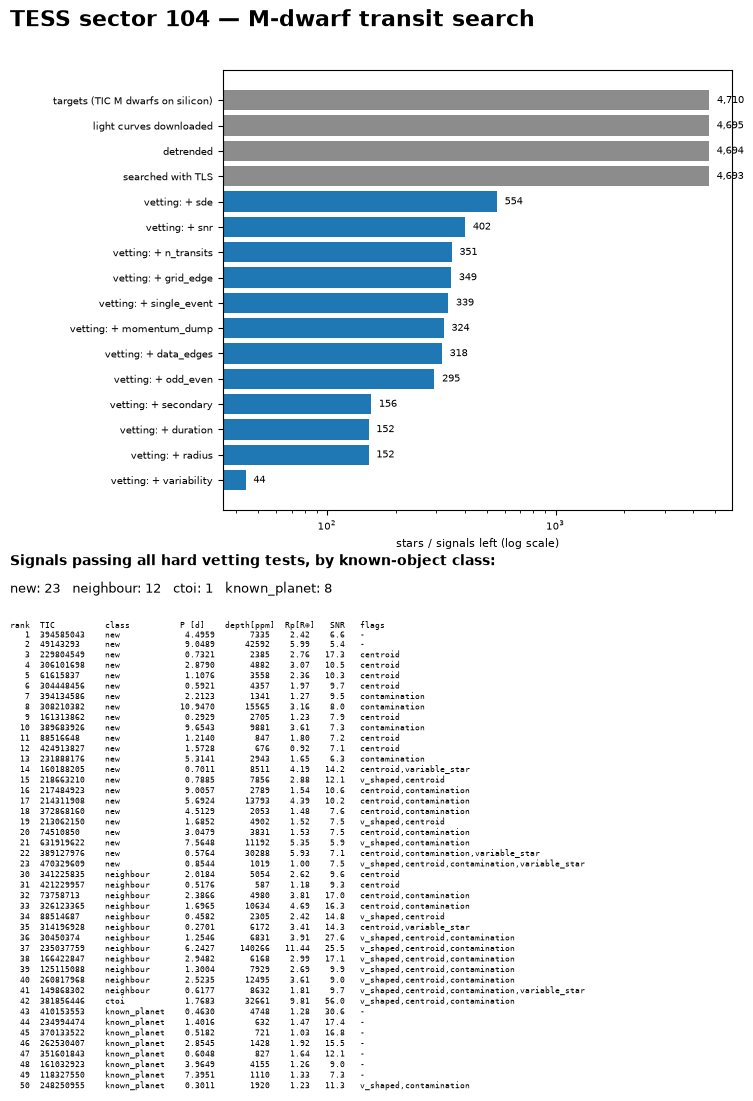

In [2]:
fig = report.summary_page(summary, pages[pages.passes_all].assign(rank=pages["rank"]))

What to notice:

- **The search keeps everyone** (4,693 of 4,694 detrended light curves). It never applies a
  threshold. Every star gets its single best signal, which is why the next number matters.
- **SDE ≥ 9 keeps 12 %** of the signals: 554 of 4,693. Under pure white noise, SDE ≥ 9 should
  happen about once in 10⁴ light curves. Twelve percent says the remaining "signals" are
  overwhelmingly real things that are not planets (variability, binaries, systematics).
- **The two biggest vetting cuts** are `secondary` (eclipsing binaries) and `variability`
  (spotted and pulsating stars). That matches what the vetting gallery in notebook 5 showed:
  among bright M dwarfs, binaries and active stars are far more common than detectable
  transiting planets.
- After vetting, step 6 sorts the survivors into known planets, blends and genuinely new
  signals. Only the last group is a discovery candidate.

## 3. Physical quantities on the page

The header of every page gives four derived numbers. They assume a **circular orbit** and the
TIC's stellar mass, radius and temperature, so they are estimates, as good as those inputs
(typically 5–10 % for M dwarfs).

**Orbital distance**, from Kepler's third law (derived in notebook 5, §8.1):

$$a = \left(\frac{G M_\star P^2}{4\pi^2}\right)^{1/3}.$$

**Insolation**: the stellar flux the planet receives, in units of what the Earth receives from
the Sun. The star's luminosity follows from the Stefan–Boltzmann law,
$L = 4\pi R_\star^2 \sigma T_{\rm eff}^4$, so relative to the Sun
$L/L_\odot = (R_\star/R_\odot)^2 (T_{\rm eff}/T_\odot)^4$, and the flux at distance a falls as
1/a²:

$$S/S_\oplus = \frac{L/L_\odot}{(a/1\,\mathrm{au})^2}.$$

**Equilibrium temperature**: the temperature at which a planet radiates exactly the power it
absorbs. A planet of radius $R_p$ intercepts the stellar flux on its cross-section $\pi R_p^2$,
absorbs a fraction $(1-A)$ (A is the albedo, the reflected fraction), and, if it redistributes
the heat over its whole surface, radiates from $4\pi R_p^2$:

$$(1-A)\,\pi R_p^2 \frac{L}{4\pi a^2} = 4\pi R_p^2\,\sigma T_{\rm eq}^4
\quad\Longrightarrow\quad
T_{\rm eq} = T_{\rm eff}\,\sqrt{\frac{R_\star}{2a}}\,(1-A)^{1/4}.$$

The page uses A = 0. It is an equilibrium value, not a surface temperature: an atmosphere can
make the surface much hotter (Venus: $T_{\rm eq}$ ≈ 230 K, surface 740 K).

`report.derived()` computes these numbers. A check on the Earth, then on LHS 3844 b, whose
published $T_{\rm eq}$ is 805 K (Vanderspek et al. 2019):

In [3]:
earth = report.derived(365.256, 1.0, 1.0, 5772)
lhs = targets.loc[410153553]
lhs_d = report.derived(known.loc[410153553, "period"], lhs.rad, lhs.mass, lhs.teff)
pd.DataFrame({"Earth (check)": earth, "LHS 3844 b": lhs_d}).round(4)

,Earth (check),LHS 3844 b
a_au,1.0001,0.0063
a_rs,215.0499,7.2172
insolation_earth,0.9999,65.1287
teq_k,278.3183,790.6779


The Earth comes out at 1 au, S = 1 and $T_{\rm eq}$ = 278 K (the textbook value for A = 0).
LHS 3844 b gets 791 K against the published 805 K. The 2 % difference comes from the TIC's
stellar parameters. Its insolation of ~65 S⊕ makes it a scorched rock, although it orbits a
star 1,000 times fainter than the Sun.

**Short periods are hot.** Around an M dwarf the habitable zone (where liquid water is
possible) lies at roughly S ≈ 0.25–1.1 S⊕ (Kopparapu et al. 2013), which for a 0.3 R☉ star
means P ≈ 10–40 days. A one-sector search (P ≤ 12 d) reaches only its inner edge, and only
around the coolest stars.

## 4. Where the candidates sit among known M-dwarf planets

Context helps judge plausibility. Below, the confirmed planets around M dwarfs (TOI catalog,
dispositions CP/KP, host Teff < 4,000 K) are shown in grey, and the planets and candidates of
this sector in colour, by class.

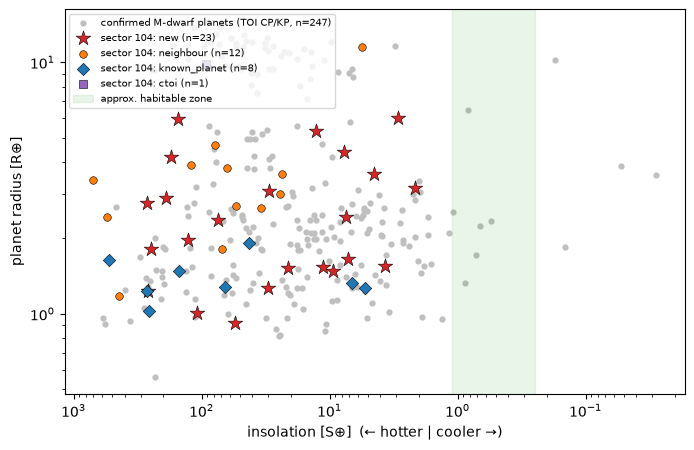

In [4]:
cat_dir = sorted((DATA_DIR / "known").glob("????-??-??"))[-1]
toi = pd.read_csv(cat_dir / "toi.csv")
ref = toi[toi["TFOPWG Disposition"].isin(["CP", "KP"]) & (toi["Stellar Eff Temp (K)"] < 4000)]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(ref["Planet Insolation (Earth Flux)"], ref["Planet Radius (R_Earth)"], s=12, color="0.75",
           label=f"confirmed M-dwarf planets (TOI CP/KP, n={len(ref)})")
style = {"new": ("C3", "*", 120), "neighbour": ("C1", "o", 30), "known_planet": ("C0", "D", 40), "ctoi": ("C4", "s", 30)}
cand = pages[pages.passes_all]
for cls, (c, m, sz) in style.items():
    sub = cand[cand.known_class == cls]
    ax.scatter(sub.insolation_earth, sub.rp_earth, s=sz, marker=m, color=c, edgecolor="k", lw=0.4,
               label=f"sector {SECTOR}: {cls} (n={len(sub)})")
ax.axvspan(0.25, 1.1, color="C2", alpha=0.1, label="approx. habitable zone")
ax.set_xscale("log"); ax.set_yscale("log"); ax.invert_xaxis()
ax.set_xlabel("insolation [S⊕]  (← hotter | cooler →)"); ax.set_ylabel("planet radius [R⊕]")
ax.legend(fontsize=7, loc="upper left")

Our known planets (blue diamonds) sit inside the cloud of confirmed planets, as they must. The
new candidates (red stars) span 1–6 R⊕ and insolations from a few to several hundred S⊕. That
region is well populated by real planets, so position alone does not make a candidate suspicious. The large ones (≳ 5 R⊕)
deserve extra suspicion, because giant planets around M dwarfs are rare. That is a population
argument, not a rule, which is why the radius test only rejects above 16.8 R⊕.

## 5. Anatomy of a page

Here is the page of LHS 3844 b, a confirmed planet, as the reference for "what a planet looks
like". `report.tls_cached` reuses the TLS result the report stored, so drawing a page takes a
second.

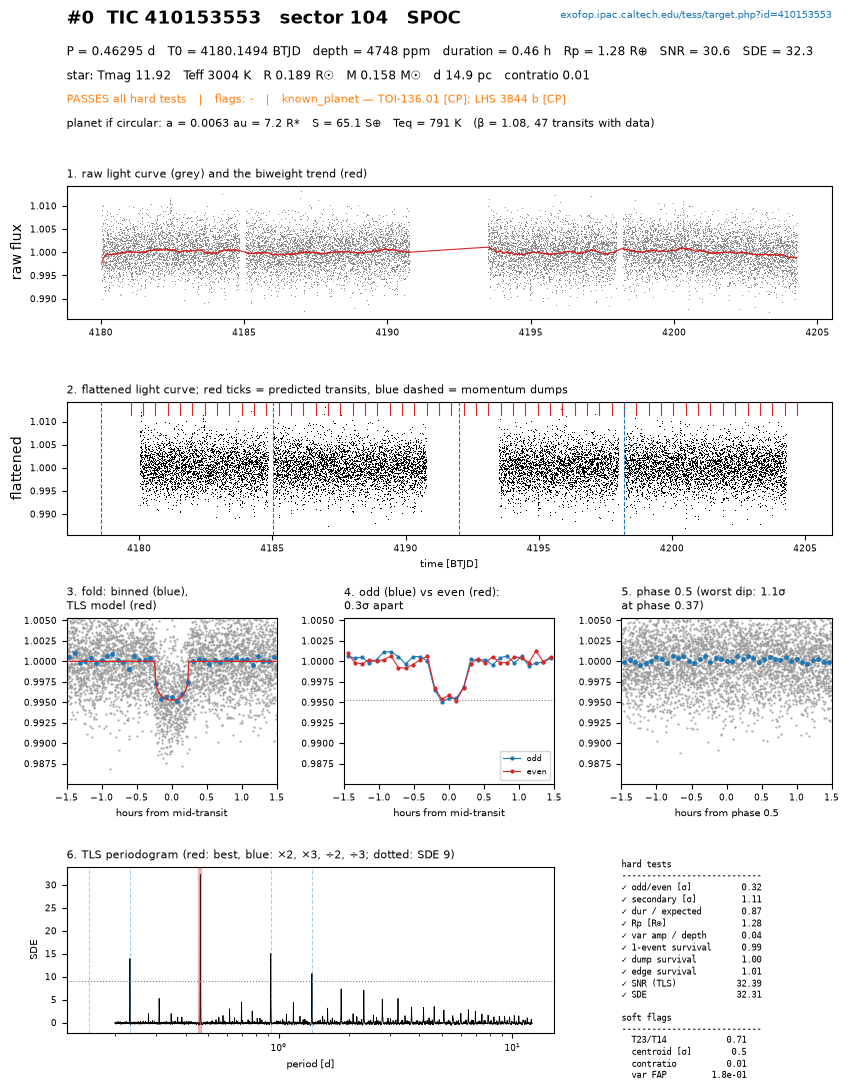

In [5]:
def page(tic_id, rank=0):
    s = known.loc[tic_id].copy()
    s["tic_id"] = tic_id
    lc = pd.read_parquet(ROOT / detrend.loc[tic_id, "file_path"])
    star = targets.loc[tic_id]
    tls = report.tls_cached(tic_id, str(ROOT / detrend.loc[tic_id, "file_path"]), star.rad, star.mass,
                            DATA_DIR / "reports" / "cache")
    fig, _ = report.candidate_page(s, star, lc, tls, DUMPS, rank, SECTOR, manifest.loc[tic_id, "author"])
    return fig


fig = page(410153553)

Panel by panel. In each case, first what a planet looks like and then what an impostor looks like.

1. **Raw light curve with the trend.** For LHS 3844 the raw flux is flat at the 0.5 % level
   and the red trend follows the slow wiggles. Look for: steps, ramps, and whether the
   transits coincide with them. The trend is where detrending can go wrong.
2. **Flattened light curve with predicted transits.** Here the transits are too shallow to see
   one by one, which is normal for small planets: each is ~3σ, and the detection comes from
   adding 47 of them. Look for: transits clustered at segment starts, at gaps, or on the
   dashed momentum-dump lines.
3. **Fold.** The defining panel. A flat baseline, a sharp ingress, a flat (U-shaped) bottom, a
   sharp egress, and the binned points following the red TLS model. Look for: a V shape
   (grazing EB), a dip much wider than the model (variability), a step (systematic).
4. **Odd/even.** The two curves must overlap. Two different depths mean an EB at half its
   period.
5. **Phase 0.5.** Flat. A dip here is a secondary eclipse, so the companion is self-luminous:
   a star.
6. **Periodogram.** One dominant spike, often with smaller spikes at 2P, 3P, P/2 (aliases:
   folding at a multiple or fraction of the period also lines up some transits). A forest of
   comparable peaks means the "best" one is not special.

The table repeats each hard test (✓/✗ with its value) and the soft flags. The header has the
derived quantities of §3.

## 6. The review procedure, with four worked cases

The review (`docs/REVIEW_sector104.md`) asks six questions per page, one per panel, in the
order above, and grades each candidate:

| grade | meaning |
|---|---|
| **A** | looks like a planet in every panel; at most one soft flag |
| **B** | plausible; one clear concern |
| **C** | weak or ambiguous |
| **D** | not a planet by eye (reason recorded) |

One extra view helps a lot: **every transit, one by one**, zoomed on the raw and flattened
flux. Real transits are individually faint but look alike. Systematics and glitches look
different from one transit to the next.

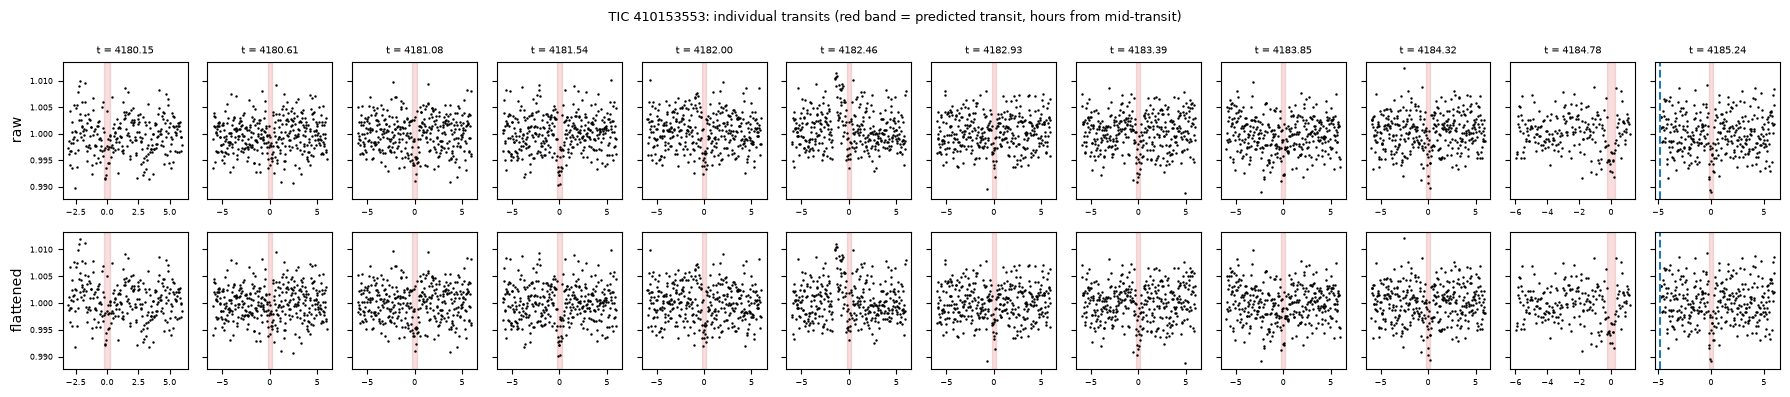

In [6]:
def transit_zooms(tic_id, max_n=12):
    s = known.loc[tic_id]
    lc = pd.read_parquet(ROOT / detrend.loc[tic_id, "file_path"])
    t = lc["time"].to_numpy()
    n0 = int(np.ceil((t.min() - s.T0) / s.period)); n1 = int(np.floor((t.max() - s.T0) / s.period))
    mids = [s.T0 + n * s.period for n in range(n0, n1 + 1)]
    mids = [m for m in mids if np.any(np.abs(t - m) < s.duration_h / 48)][:max_n]
    w = max(4 * s.duration_h / 24, 0.25)
    fig, axes = plt.subplots(2, len(mids), figsize=(min(1.6 * len(mids), 18), 4), sharey="row", squeeze=False)
    for j, m in enumerate(mids):
        sel = np.abs(t - m) < w
        for i, col in enumerate(["flux_raw", "flux"]):
            ax = axes[i, j]
            ax.plot((t[sel] - m) * 24, lc[col].to_numpy()[sel], ".", ms=1.5, color="k")
            ax.axvspan(-s.duration_h / 2, s.duration_h / 2, color="C3", alpha=0.15)
            for d in DUMPS:
                if abs(d - m) < w:
                    ax.axvline((d - m) * 24, color="C0", ls="--")
            ax.tick_params(labelsize=6)
        axes[0, j].set_title(f"t = {m:.2f}", fontsize=7)
    axes[0, 0].set_ylabel("raw"); axes[1, 0].set_ylabel("flattened")
    fig.suptitle(f"TIC {tic_id}: individual transits (red band = predicted transit, hours from mid-transit)", fontsize=9)
    plt.tight_layout()


transit_zooms(410153553)

For LHS 3844 b each transit is buried in noise. That is expected, and each one is "a few
low points" consistent with the others. Nothing stands out.

### Case 1, grade A: TIC 306101698

The best new candidate in the sector.

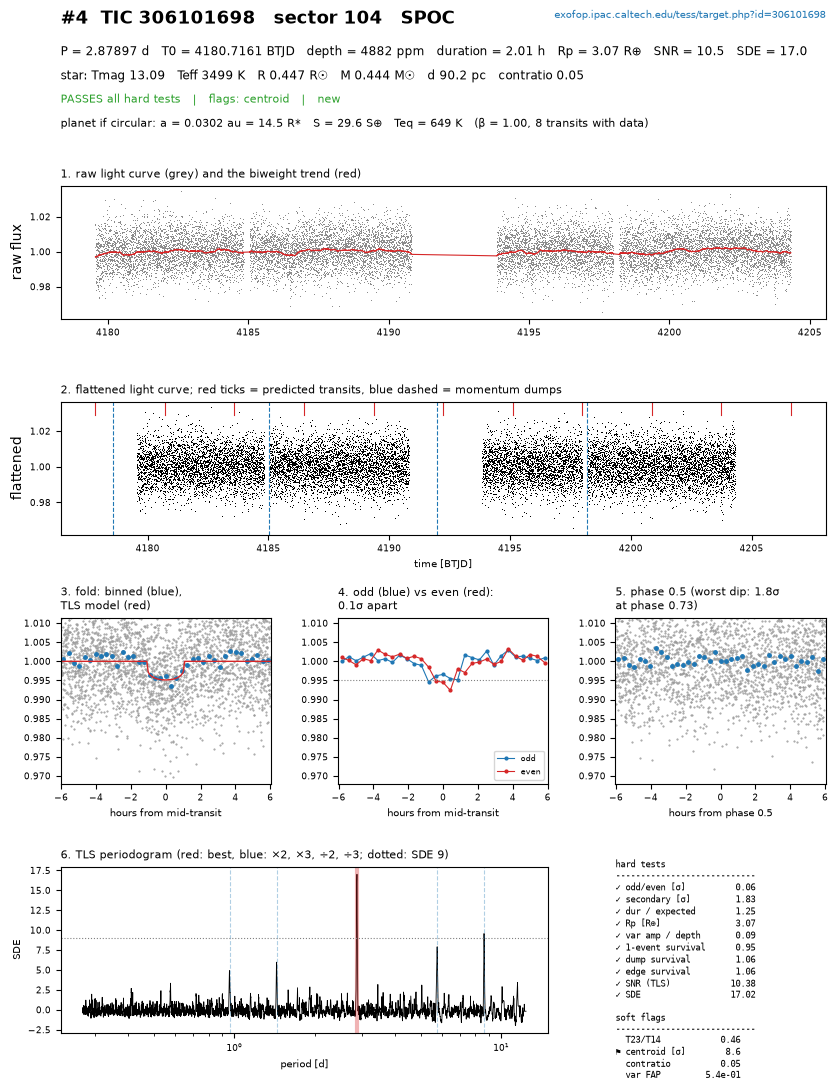

In [7]:
fig = page(306101698, 4)

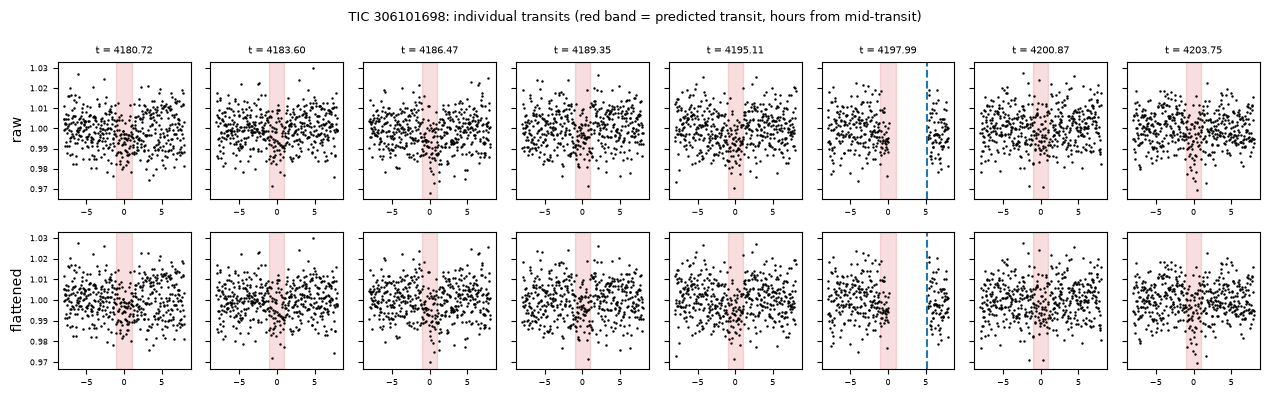

In [8]:
transit_zooms(306101698)

Every panel reads like the LHS 3844 page. A quiet star, a flat-bottomed 2-hour transit, odd
and even identical (0.06σ), nothing at phase 0.5, and a periodogram with one spike plus its
aliases. The individual transits are each visible as a ~0.5 % dip of the right length. The one
concern is the soft `centroid` flag (8.6σ). The light centroid moves during transit, so part of
the signal could come from a neighbour. That cannot be settled from this page. It needs the
pixel data (notebook 9).

### Case 2, grade D (systematics): TIC 49143293

Ranked #2 by the pipeline, with a 4 % deep, 6 R⊕ "planet" and no soft flags at all.

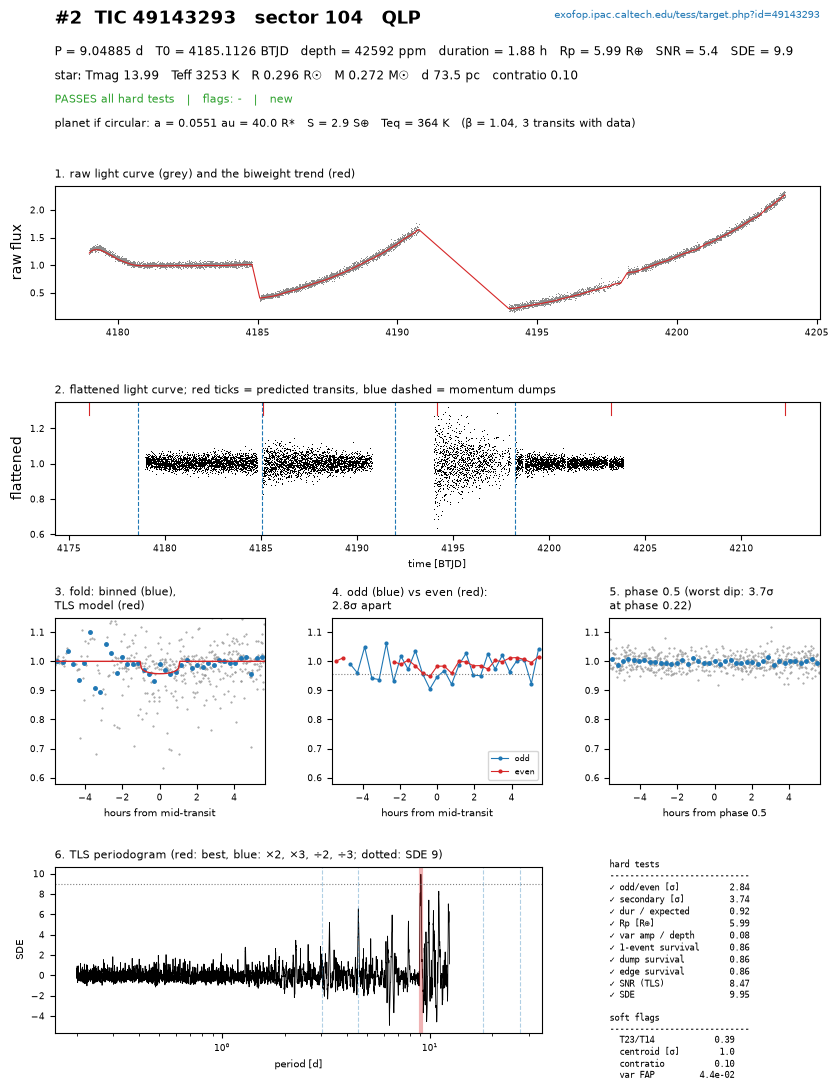

In [9]:
fig = page(49143293, 2)

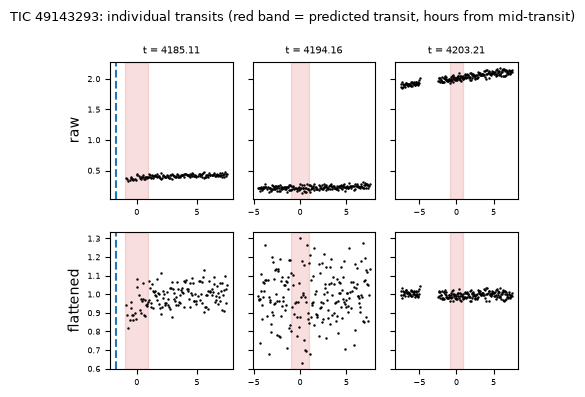

In [10]:
transit_zooms(49143293)

Panel 1 gives it away: the QLP flux jumps from 1.0 to 0.4 and climbs back to 2.0. These are
huge background/scattered-light systematics. The zooms show three "transits" that look nothing
alike: one at the start of a segment, one on the momentum dump at 4185.04, one in the noisy
stretch after the mid-sector gap. Vetting v2 already shrinks its SNR from 8.5 (TLS) to 5.4 (our
local-noise SNR). It still passes only because the SNR test uses TLS's number, a choice that
notebook 8 revisits with injections.

### Case 3, grade D (glitches): TIC 394134586

A bright (T = 10.3), nearby (19 pc) star, with a 1.3 R⊕ signal that passes every hard test.

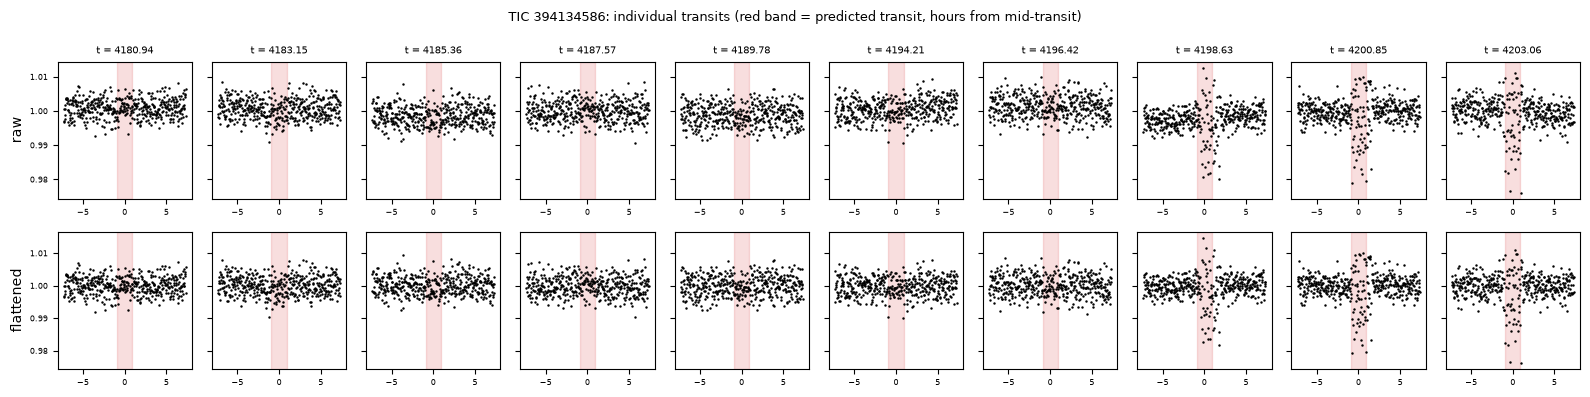

In [11]:
transit_zooms(394134586)

In the second orbit, the last three predicted transits (t ≈ 4198.6, 4200.9, 4203.1) each
contain a **short burst of strongly increased scatter**: points between +1 % and −2 %, within
about an hour. Its *mean* is low, so it reads as a dip. The seven earlier transits show nothing
at all, although a real 1,300-ppm transit would be as deep in them as in the others. The burst
is confined to the transit window, so even the local-noise estimate (taken *outside* the
transits) does not see it. A test of the in-transit scatter against the out-of-transit
scatter would. Averaged over the transit window, each spike looks like a modest dip, and three of
them at the right spacing make a "periodic signal". No current test checks whether the
in-transit points behave like a transit (shifted down, same scatter) rather than like noise
(same mean, larger scatter). The review notes this as an open improvement.

### Case 4, grade D (likely blend): TIC 218663210

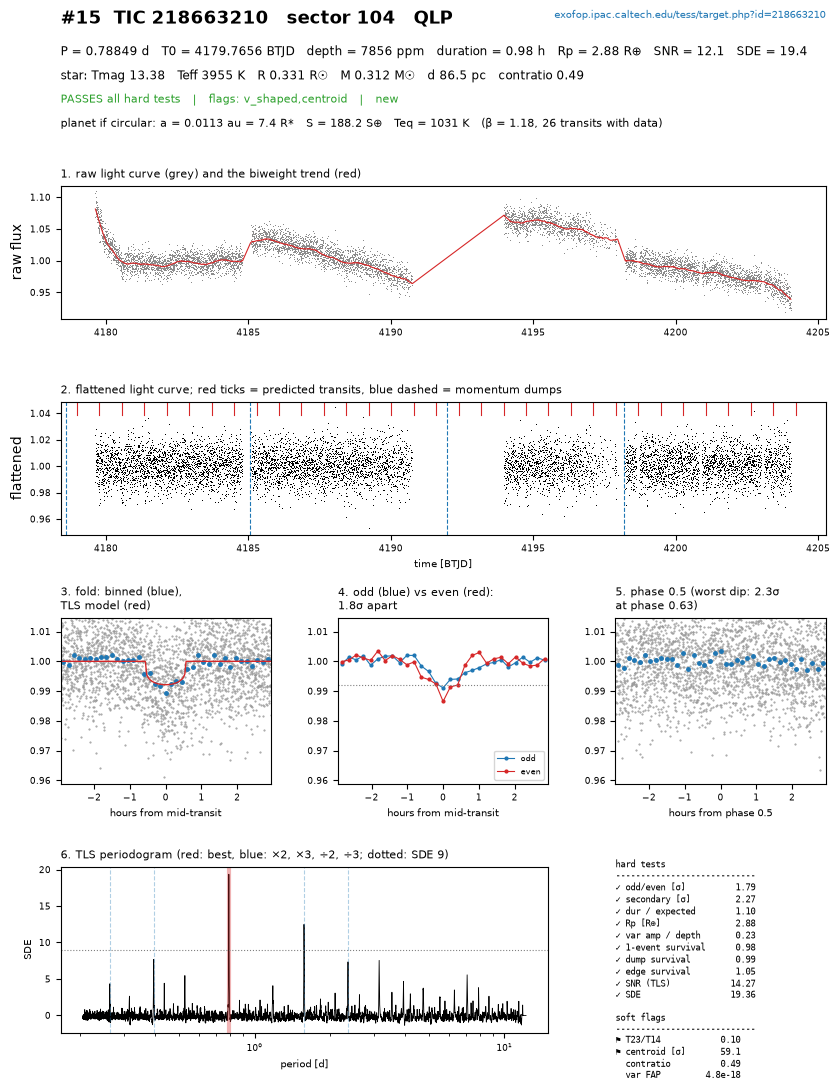

In [12]:
fig = page(218663210, 15)

The fold is a V (T23/T14 = 0.10, so no flat bottom). The centroid moves by **59σ** during
transit, and `contratio` = 0.49 says a third of the aperture's light comes from neighbours.
This is the textbook signature of a background eclipsing binary. A V-shaped eclipse diluted
by our star's light imitates a 0.8 % transit. A grazing planet could also be V-shaped, but
not together with that centroid shift.

## 7. From review to pipeline changes

Grading by eye is subjective, so its value lies in the **patterns**. When the same failure
appears several times, it becomes a test. The first review (vetting v1) produced four such
changes (notebook 5, §12.1). This review leaves three open: glitch-driven signals (case 3),
strong ramps, and frequent centroid shifts. All are recorded in `docs/REVIEW_sector104.md`.
The opposite direction matters just as much. Every new test must be checked on the known
planets and on injected planets (notebook 8), so that it removes impostors without removing
planets.